In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
columns = [
    'Sex',
    'Length',
    'Diameter',
    'Height',
    'Whole_weight',
    'Shucked_weight',
    'Viscera_weight',
    'Shell_weight',
    'Rings'
]

df = pd.read_csv(
    'abalone.data',
    header=None,
    names=columns
)

In [3]:
df.head()

,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [4]:
df.shape

(4177, 9)

In [5]:
df.isnull().sum()

Sex               0
Length            0
Diameter          0
Height            0
Whole_weight      0
Shucked_weight    0
Viscera_weight    0
Shell_weight      0
Rings             0
dtype: int64

In [6]:
duplicate_rows_df = df[df.duplicated()]
print("number of duplicate rows: ", duplicate_rows_df.shape)

number of duplicate rows:  (0, 9)


## Descriptive Statistics Variable "Sex"

The variable "Sex" contains three distinct categories: Male (M), Female (F), and Infant (I). We examined the frequency of observations within each category and calculated their relative proportions, expressed as percentages. Additionally, a bar chart was used to visually represent the distribution of observations across the three categories.


In [7]:
df["Sex"].unique() 

<StringArray>
['M', 'F', 'I']
Length: 3, dtype: str

In [8]:
df['Sex'].value_counts()

Sex
M    1528
I    1342
F    1307
Name: count, dtype: int64

In [9]:
df['Sex'].value_counts(normalize=True) * 100

Sex
M    36.581278
I    32.128322
F    31.290400
Name: proportion, dtype: float64

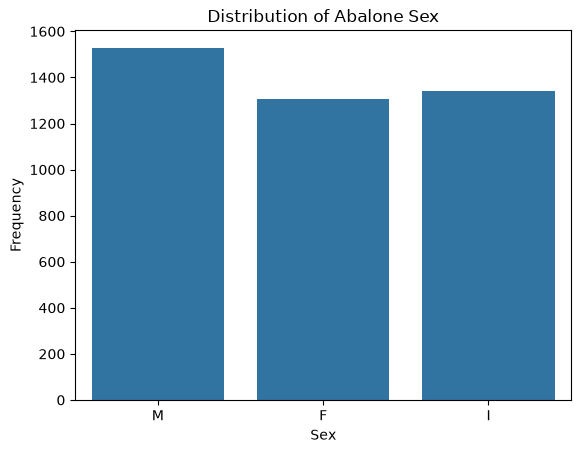

In [10]:
sns.countplot(data=df, x='Sex')

plt.title('Distribution of Abalone Sex')
plt.xlabel('Sex')
plt.ylabel('Frequency')
plt.show()

## Descriptive statistics for the "Length" category

For the “Length” variable, the data were initially examined for missing or potentially erroneous values. No missing values ​​were identified. Subsequently, a histogram was constructed to visualize the length distribution of the abalone. Additionally, a boxplot was used to examine the median, quartiles, interquartile range (IQR), minimum and maximum values, and possible outliers.

49 potential outliers were identified, representing approximately 1.17% of the total observations. The majority of these observations (41) corresponded to the “infant” category (*Infant*).

Finally, a histogram with distributions differentiated by sex was generated to compare the length of the abalone between the three categories. The results showed that abalones in the "child" category have a shorter average length of approximately 0.4, while abalone in the "male" and "female" categories show distributions with higher and relatively similar values, with a considerable overlap of around 0.6.

In [11]:
df['Length'].unique() 

array([0.455, 0.35 , 0.53 , 0.44 , 0.33 , 0.425, 0.545, 0.475, 0.55 ,
       0.525, 0.43 , 0.49 , 0.535, 0.47 , 0.5  , 0.355, 0.365, 0.45 ,
       0.38 , 0.565, 0.615, 0.56 , 0.58 , 0.59 , 0.605, 0.575, 0.68 ,
       0.665, 0.705, 0.465, 0.54 , 0.24 , 0.205, 0.21 , 0.39 , 0.46 ,
       0.325, 0.52 , 0.4  , 0.485, 0.405, 0.445, 0.245, 0.505, 0.595,
       0.31 , 0.555, 0.57 , 0.6  , 0.62 , 0.625, 0.695, 0.36 , 0.51 ,
       0.435, 0.495, 0.385, 0.515, 0.37 , 0.27 , 0.375, 0.7  , 0.71 ,
       0.265, 0.305, 0.345, 0.65 , 0.28 , 0.175, 0.17 , 0.635, 0.645,
       0.61 , 0.725, 0.235, 0.315, 0.225, 0.64 , 0.63 , 0.585, 0.42 ,
       0.335, 0.415, 0.275, 0.295, 0.075, 0.13 , 0.11 , 0.16 , 0.23 ,
       0.3  , 0.32 , 0.655, 0.66 , 0.2  , 0.165, 0.19 , 0.74 , 0.34 ,
       0.675, 0.745, 0.685, 0.69 , 0.67 , 0.29 , 0.26 , 0.395, 0.41 ,
       0.22 , 0.255, 0.735, 0.155, 0.48 , 0.195, 0.25 , 0.18 , 0.15 ,
       0.215, 0.73 , 0.715, 0.765, 0.185, 0.285, 0.72 , 0.75 , 0.755,
       0.78 , 0.815,

In [12]:
df['Length'].agg(['min', 'max'])

min    0.075
max    0.815
Name: Length, dtype: float64

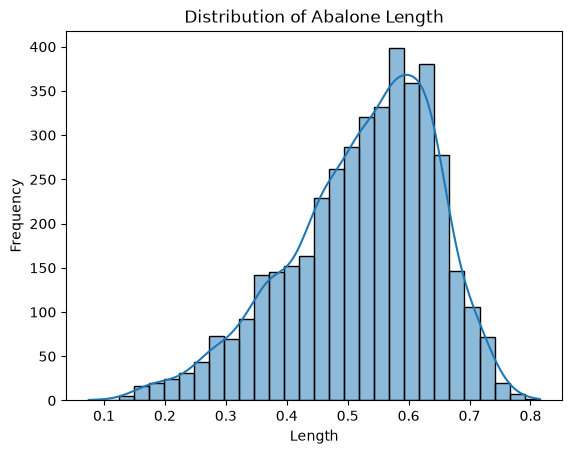

In [13]:
sns.histplot(data=df, x='Length', bins=30, kde=True)

plt.title('Distribution of Abalone Length')
plt.xlabel('Length')
plt.ylabel('Frequency')
plt.show()

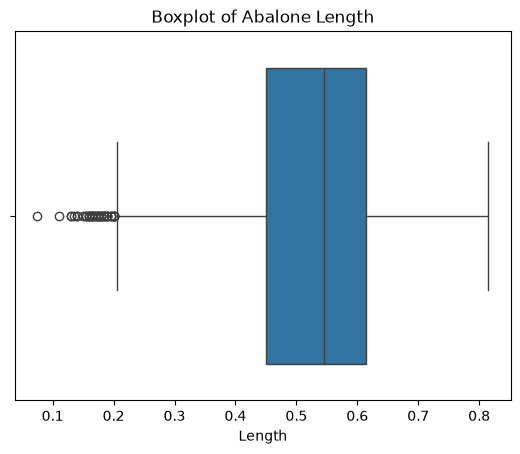

In [14]:
sns.boxplot(data=df, x='Length')

plt.title('Boxplot of Abalone Length')
plt.xlabel('Length')
plt.show()

In [34]:
Q1_length = df['Length'].quantile(0.25)
Q3_length = df['Length'].quantile(0.75)

IQR_length = Q3_length - Q1_length

print('Q1 Length:', Q1_length)
print('Q3 Length:', Q3_length)
print('IQR Length:', IQR_length)

Q1 Length: 0.45
Q3 Length: 0.615
IQR Length: 0.16499999999999998


In [35]:
lower_limit_length = Q1_length - (1.5 * IQR_length)
upper_limit_length = Q3_length + (1.5 * IQR_length)

print('Lower limit Length:', lower_limit_length)
print('Upper limit Length:', upper_limit_length)

Lower limit Length: 0.20250000000000004
Upper limit Length: 0.8624999999999999


In [36]:
outliers_length = df[
    (df['Length'] < lower_limit_length) |
    (df['Length'] > upper_limit_length)
]

print('Number of Length outliers:', len(outliers_length))

Number of Length outliers: 49


In [37]:
outlier_percentage_length = (len(outliers_length) / len(df)) * 100

print('Length outlier percentage:', round(outlier_percentage_length, 2), '%')

Length outlier percentage: 1.17 %


In [51]:
outliers_length['Sex'].value_counts()

Sex
I    41
M     8
Name: count, dtype: int64

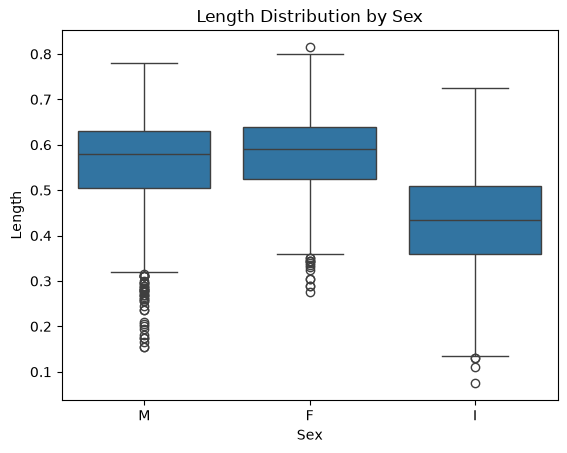

In [19]:
sns.boxplot(data=df, x='Sex', y='Length')

plt.title('Length Distribution by Sex')
plt.xlabel('Sex')
plt.ylabel('Length')
plt.show()

In [20]:
df.groupby('Sex')['Length'].describe()

,count,mean,std,min,25%,50%,75%,max
Sex,,,,,,,,
F,1307.0,0.579093,0.086160,0.275,0.525,0.590,0.64,0.815
I,1342.0,0.427746,0.108858,0.075,0.360,0.435,0.51,0.725
M,1528.0,0.561391,0.102697,0.155,0.505,0.580,0.63,0.780


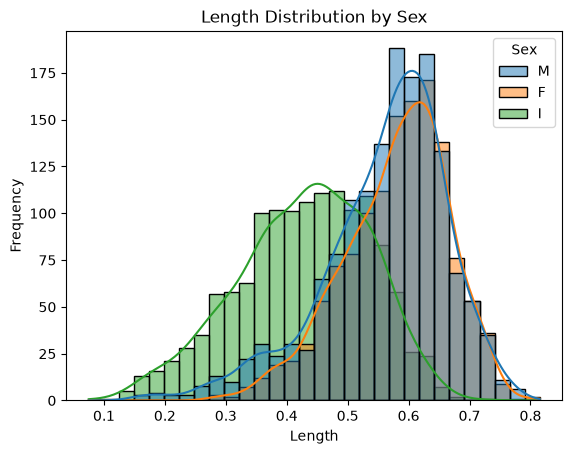

In [21]:
sns.histplot(
    data=df,
    x='Length',
    hue='Sex',
    kde=True,
    bins=30
)

plt.title('Length Distribution by Sex')
plt.xlabel('Length')
plt.ylabel('Frequency')
plt.show()

## Descriptive statistics for the "Diameter" category

A similar analysis was conducted for the "Diameter" variable; no missing values ​​were identified, and the distribution showed patterns comparable to those observed for the "Length" variable.

Using the interquartile range (IQR) method, 59 potential outliers were identified, representing approximately 1.41% of the total observations. The majority of these (50) belonged to the "Infant" category, consistent with the findings for the previously analyzed variable.

Box plots were used to compare the diameter across the three sex categories. The results revealed patterns similar to those observed for length. Furthermore, the histograms indicated that abalones in the "Infant" category have a smaller average diameter (approximately 0.30) compared to those in the "Male" and "Female" categories, which show average values ​​of approximately 0.45.

In [38]:
df['Diameter'].unique()

array([0.365, 0.265, 0.42 , 0.255, 0.3  , 0.415, 0.425, 0.37 , 0.44 ,
       0.38 , 0.35 , 0.405, 0.355, 0.4  , 0.28 , 0.34 , 0.295, 0.32 ,
       0.275, 0.48 , 0.45 , 0.445, 0.475, 0.47 , 0.56 , 0.525, 0.55 ,
       0.29 , 0.335, 0.175, 0.15 , 0.375, 0.245, 0.41 , 0.36 , 0.31 ,
       0.385, 0.19 , 0.345, 0.325, 0.495, 0.39 , 0.235, 0.51 , 0.465,
       0.535, 0.435, 0.43 , 0.395, 0.305, 0.195, 0.54 , 0.26 , 0.2  ,
       0.33 , 0.23 , 0.285, 0.52 , 0.455, 0.205, 0.13 , 0.5  , 0.515,
       0.485, 0.46 , 0.545, 0.57 , 0.575, 0.16 , 0.21 , 0.49 , 0.25 ,
       0.27 , 0.505, 0.215, 0.225, 0.055, 0.1  , 0.09 , 0.12 , 0.53 ,
       0.145, 0.22 , 0.6  , 0.58 , 0.585, 0.565, 0.555, 0.185, 0.165,
       0.125, 0.59 , 0.14 , 0.11 , 0.155, 0.315, 0.24 , 0.17 , 0.18 ,
       0.105, 0.595, 0.135, 0.625, 0.63 , 0.61 , 0.65 , 0.62 , 0.605,
       0.095, 0.115, 0.615])

In [39]:
df['Diameter'].agg(['min', 'max'])

min    0.055
max    0.650
Name: Diameter, dtype: float64

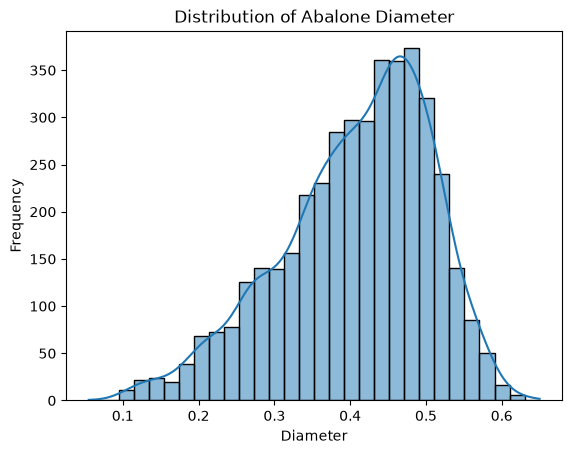

In [40]:
sns.histplot(data=df, x='Diameter', bins=30, kde=True)

plt.title('Distribution of Abalone Diameter')
plt.xlabel('Diameter')
plt.ylabel('Frequency')
plt.show()

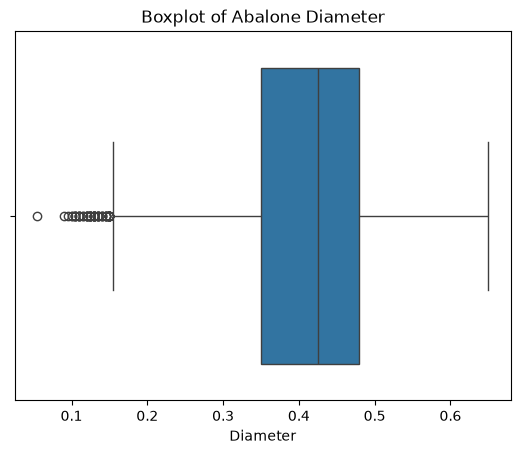

In [41]:
sns.boxplot(data=df, x='Diameter')

plt.title('Boxplot of Abalone Diameter')
plt.xlabel('Diameter')
plt.show()

In [44]:
Q1_diameter = df['Diameter'].quantile(0.25)
Q3_diameter = df['Diameter'].quantile(0.75)

IQR_diameter = Q3_diameter - Q1_diameter

print('Q1 Diameter:', Q1_diameter)
print('Q3 Diameter:', Q3_diameter)
print('IQR Diameter:', IQR_diameter)

Q1 Diameter: 0.35
Q3 Diameter: 0.48
IQR Diameter: 0.13


In [45]:
lower_limit_diameter = Q1_diameter - (1.5 * IQR_diameter)
upper_limit_diameter = Q3_diameter + (1.5 * IQR_diameter)

print('Lower limit Diameter:', lower_limit_diameter)
print('Upper limit Diameter:', upper_limit_diameter)

Lower limit Diameter: 0.15499999999999997
Upper limit Diameter: 0.675


In [46]:
outliers_diameter = df[
    (df['Diameter'] < lower_limit_diameter) |
    (df['Diameter'] > upper_limit_diameter)
]

print('Number of Diameter outliers:', len(outliers_diameter))

Number of Diameter outliers: 59


In [47]:
outlier_percentage_diameter = (len(outliers_diameter) / len(df)) * 100

print('Diameter outlier percentage:', round(outlier_percentage_diameter, 2), '%')

Diameter outlier percentage: 1.41 %


In [52]:
outliers_diameter['Sex'].value_counts()

Sex
I    50
M     9
Name: count, dtype: int64

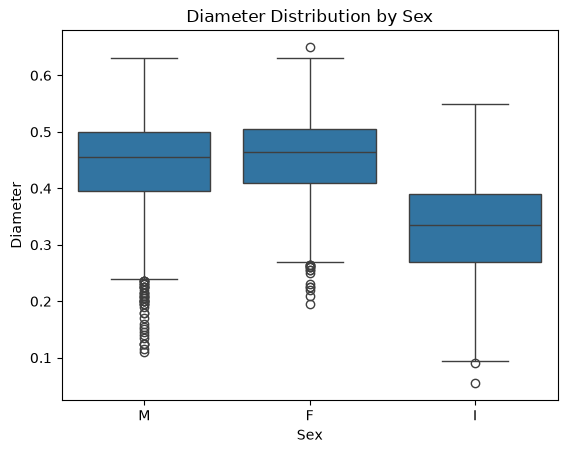

In [48]:
sns.boxplot(data=df, x='Sex', y='Diameter')

plt.title('Diameter Distribution by Sex')
plt.xlabel('Sex')
plt.ylabel('Diameter')
plt.show()

In [49]:
df.groupby('Sex')['Diameter'].describe()

,count,mean,std,min,25%,50%,75%,max
Sex,,,,,,,,
F,1307.0,0.454732,0.070954,0.195,0.410,0.465,0.505,0.65
I,1342.0,0.326494,0.088109,0.055,0.270,0.335,0.390,0.55
M,1528.0,0.439287,0.084398,0.110,0.395,0.455,0.500,0.63


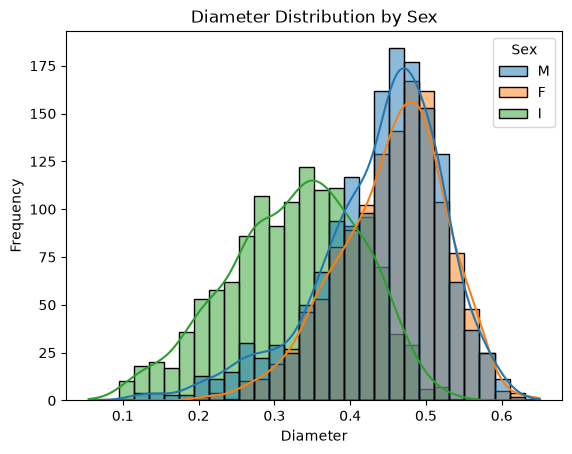

In [50]:
sns.histplot(
    data=df,
    x='Diameter',
    hue='Sex',
    kde=True,
    bins=30
)

plt.title('Diameter Distribution by Sex')
plt.xlabel('Diameter')
plt.ylabel('Frequency')
plt.show()